# Project Module 3: Implementation
**Community Detection**

*2MBS80 - Complex Networks*

Submission by **Project Group 6** with the following group members:
- Huy Hong (1935569)
- Andrei Sirbu (2126133)
- Tjerk Williams

### Table of Contents
1. [Imports](#imports)
2. [Problem 1](#problem-1)
    - [Estimating the number of communities in a graph](#procedure)
    - [Procedure testing](#testing)
    - [Procedure evaluation](#procedure-eval)
3. [Problem 2](#problem-2)
    - [Choice of real-life network](#rl-network)
    - [Spectral clustering](#sc)
    - [Louvain's algorithm](#louvain)
    - [Partition agreement measure](#measure)
    - [Evaluation](#measure-eval)

## Imports <a name="imports" id="imports"></a>
These are the packages and prerequisites required for running the code.

In [2]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import mmread
from collections import deque
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

SEED = 2026

## Problem 1 <a name="problem-1" id="problem-1"></a>
Design a procedure to estimate the number of communities in a graph, explaining
what feature of the graph it uses and why.

Test your procedure on stochastic block models with different numbers of communities and different levels of separation. Use repeated samples to account for randomness, and present your estimates against the planted numbers in a clear figure. When does your procedure succeed, and where does it fail? Investigate one weakness of your approach.

### Estimating the number of communities in a graph <a name="procedure" id="procedure"></a>

Our procedure estimates the number of communities by **peeling them off one at a time**:

1. Pick the highest-degree remaining vertex as the seed.
2. Grow a community around the seed with one of the expansion rules below.
3. Remove the community's vertices from the graph and repeat until no edges remain.

Only communities with at least `min_size = 20` vertices are counted, so small leftover fragments are not mistaken for communities.

**Feature used: modularity.** A vertex joins a community only if it increases the modularity gain

$$\Delta Q(v) = k_{\text{in}}(v) - \gamma \frac{d_v K_C}{2m}$$

where $k_{\text{in}}(v)$ is the number of edges from $v$ into the community, $d_v$ is the degree of $v$, $K_C$ is the total degree of the community, and $m$ is the number of edges. Modularity measures whether a group is denser inside than expected under a random graph with the same degrees, which is what we mean by a community. Unlike spectral clustering, the procedure does not need K as an input.

In [3]:
def find_community_bfs(G, seed, gamma = 1.0):
    """ 
    Picks the highest-degree remaining vertex and then expand the community around this vertex by adding vertex layers via BFS.

    Parameters:
    :G: Graph
    :seed: Starting vertex
    :gamma: Resolution parameter (default is 1)
    :return: Community
    """
    C = {seed}
    d = dict(G.degree())

    distance = {seed: 0}
    queue = deque([seed])
    max_dist = 0

    while queue:
        u = queue.popleft()

        for v in G.neighbors(u):
            if v not in distance:
                distance[v] = distance[u] + 1
                max_dist = max(max_dist, distance[v])
                queue.append(v)

    for k in range(1, max_dist + 1):
        layer = [v for v, dist in distance.items() if dist == k and v not in C]
        if not layer:
            break

        added_vertices = False
        for v in sorted(layer, key = lambda x: -d[x]):
            sum_d_C = sum(d[u] for u in C)
            edges_to_C = sum(1 for u in G.neighbors(v) if u in C)
            mod_gain = edges_to_C - gamma * d[v] * sum_d_C / (2 * G.number_of_edges())

            if mod_gain > 0:
                C.add(v)
                added_vertices = True

        if not added_vertices:
            break

    return C

In [4]:
def find_community_greedy(G, seed, gamma = 1.0):
    """
    Checks each vertex and adds the neighbor with the largest modularity gain as a greedy choice, where we stop once the best gain is no longer positive.

    Parameters:
    :G: Graph
    :seed: Starting vertex
    :gamma: Resolution parameter (default is 1)
    :return: Community
    """
    C = {seed} # Initialize community
    d = dict(G.degree()) # Keep track of vertex degrees

    edges_to_C = {u: 1 for u in G.neighbors(seed)}
    next_v = set(edges_to_C) # Set of edges to a vertex's neighbors
    sum_d_C = d[seed]

    # While there is an untraversed edge from a vertex to its neighbor, we first compute the vertex with the highest modularity gain
    while next_v:
        best_v = None
        best_gain = 0.0

        for v in next_v:
            mod_gain = edges_to_C[v] - gamma * d[v] * sum_d_C / (2 * G.number_of_edges())

            # Update the best modularity gain and the vertex resulting in this gain, if a higher value is found.
            if mod_gain > best_gain:
                best_gain = mod_gain
                best_v = v

        # There exists no vertex with a better modularity gain value.
        if best_v is None:
            break

        C.add(best_v) # Add the vertex with the highest modularity gain in the community as the 'centroid'
        sum_d_C += d[best_v]
        next_v.discard(best_v) # Remove the vertex with the highest modularity gain after it has been added to a community

        # Continuing checking the modularity for the neighbors of the 'best vertex'
        for u in G.neighbors(best_v):
            if u in C:
                continue
            if u in edges_to_C:
                edges_to_C[u] += 1
            else:
                edges_to_C[u] = 1
            next_v.add(u)

    return C

### Expansion rules

**BFS:** From the seed, compute the BFS distance of every vertex in the remaining graph. For $k = 1, 2, \dots$, consider the vertices at distance $k$ that are not yet in the community, in decreasing degree order, and add each one whose gain is positive, computed against the current community. Stop when a whole layer adds nothing.

**Greedy:** Keep the set of vertices adjacent to the community. At each step, compute the gain of every candidate, add the candidate with the largest gain, and stop when no candidate has a positive gain.

Both rules use only the observed graph. Gains are computed on the residual graph, the graph that remains after earlier communities have been removed.

In [5]:
def community_number_estimator(G, estimator, gamma = 1.0, min_size = 20, return_communities = False):
    """
    Expand a community from the highest-degree remaining vertex, remove it, and repeat until no edges remain.
    Communities smaller than min_size are not counted.

    Parameters:
    :G: Graph
    :estimator: Community expansion function with signature estimator(H, seed, gamma)
    :gamma: Resolution parameter
    :min_size: Minimum community size to count
    :return_communities: If True, also return the list of counted communities
    :return: Number of communities, and the communities if return_communities is True
    """
    H = G.copy()
    communities = []

    while H.number_of_edges() > 0:
        seed = max(H.nodes(), key = lambda v: H.degree(v))

        # Vertex is isolated
        if H.degree(seed) == 0:
            break

        # Form a community and keep it
        C = estimator(H, seed, gamma)
        communities.append(C)

        # Remove community from graph
        H.remove_nodes_from(C)

    big = [C for C in communities if len(C) >= min_size]
    if return_communities:
        return len(big), big
    return len(big)

### Procedure testing <a name="testing" id="testing"></a>

We test on stochastic block models with $n = 300$ vertices, $q_{\text{in}} = 0.3$, and 10 samples per setting. Unless stated otherwise, $q_{\text{out}} = 0.02$. For each setting we report the mean and standard deviation of the estimated K against the planted K. Two things vary:

- the number of planted communities, $K \in \{2, \dots, 6\}$;
- the separation between communities, $q_{\text{out}} \in [0.005, 0.20]$.

In [6]:
def SBM_K(K_values, n, q_in, q_out, n_samples):
    """ 
    Generate an SBM for different values of the number of communities K

    Parameters:
    :K_values: Number of communities generated by the SBM
    :n: Number of vertices
    :q_in: Probability that two nodes are in the same community
    :q_out: Probability that two nodes are in different communities
    :n_samples: Number of samples for the SBM
    :return: The number of esitmated communities
    """
    results = {K: {"bfs": [], "greedy": []} for K in K_values}

    for K in K_values:
        sizes = [n // K] * K
        sizes[0] += n - sum(sizes)

        # Generate the SBM matrix
        Q = [[q_in if i == j else q_out for j in range(K)] for i in range(K)]

        for s in range(n_samples):
            G = nx.stochastic_block_model(sizes, Q, seed = SEED + s)
            results[K]["bfs"].append(community_number_estimator(G, find_community_bfs))
            results[K]["greedy"].append(community_number_estimator(G, find_community_greedy))

    return results


K_values = [2, 3, 4, 5, 6]
n = 300
q_in = 0.3
q_out = 0.02
n_samples = 10

res_K = SBM_K(K_values, n, q_in, q_out, n_samples)

print("Number of communities | BFS method (mean ± std) | Greedy method (mean ± std)")
print("----------------------------------------------------------------------------")
for K in K_values:
    bm = np.mean(res_K[K]["bfs"]);  bs = np.std(res_K[K]["bfs"])
    gm = np.mean(res_K[K]["greedy"]);  gs = np.std(res_K[K]["greedy"])
    print(f" {K:2d} | {bm:4.1f} ± {bs:4.2f} | {gm:4.1f} ± {gs:4.2f}")

Number of communities | BFS method (mean ± std) | Greedy method (mean ± std)
----------------------------------------------------------------------------
  2 |  3.9 ± 0.30 |  3.5 ± 0.50
  3 |  4.0 ± 0.00 |  3.9 ± 0.30
  4 |  4.2 ± 0.40 |  4.3 ± 0.46
  5 |  4.7 ± 0.46 |  5.0 ± 0.00
  6 |  4.9 ± 0.54 |  5.3 ± 0.46


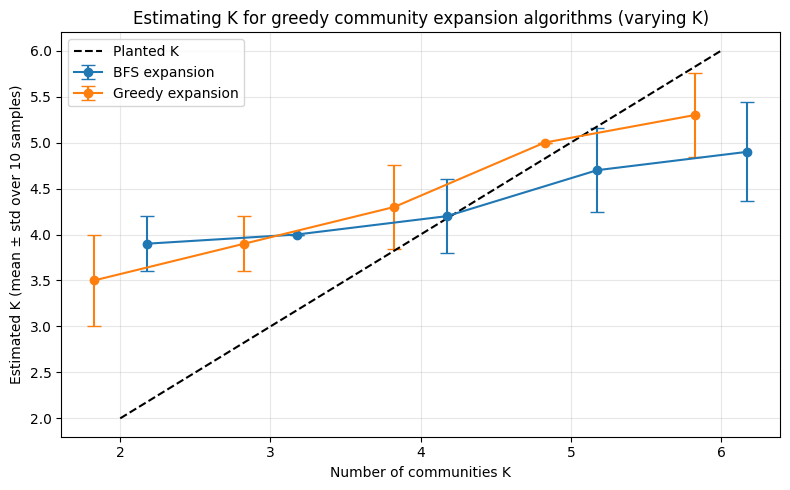

In [7]:
# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(K_values))
w = 0.35

ax.errorbar(x + w/2,
            [np.mean(res_K[K]["bfs"])    for K in K_values],
            yerr=[np.std(res_K[K]["bfs"]) for K in K_values],
            fmt = "o-", capsize = 5, label = "BFS expansion")
ax.errorbar(x - w/2,
            [np.mean(res_K[K]["greedy"])    for K in K_values],
            yerr=[np.std(res_K[K]["greedy"]) for K in K_values],
            fmt = "o-", capsize = 5, label = "Greedy expansion")
ax.plot(x, K_values, "k--", label = "Planted K")

ax.set_xticks(x)
ax.set_xticklabels(K_values)
ax.set_xlabel("Number of communities K")
ax.set_ylabel("Estimated K (mean ± std over 10 samples)")
ax.set_title("Estimating K for greedy community expansion algorithms (varying K)")
ax.legend()
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

**Reading the K sweep.** Both methods track K only loosely.

- **Small K is overestimated.** At K = 2 the methods return 3.9 (BFS) and 3.5 (greedy). At K = 3 both return about 4.
- **Large K is underestimated.** At K = 6 they return 4.9 (BFS) and 5.3 (greedy).
- The estimate crosses the planted line around K = 4 and 5.

The estimate increases with K, so the procedure responds to the structure, but it does not reach the planted value at either end.

In [8]:
def SBM_separation(q_out_values, K, n, q_in, n_samples):
    """ 
    Generate an SBM for different values of the probability q_out, which is the probability that any two nodes are in different communities

    Parameters:
    :q_out_values: Probabilities that two nodes are in different communities
    :K: Number of communities generated by the SBM
    :n: Number of vertices
    :q_in: Probability that two nodes are in the same community
    :n_samples: Number of samples for the SBM
    :return: The number of esitmated communities
    """
    results = {q: {"bfs": [], "greedy": []} for q in q_out_values}
    sizes = [n // K] * K
    sizes[0] += n - sum(sizes)

    for q_out in q_out_values:
        Q = [[q_in if i == j else q_out for j in range(K)] for i in range(K)]

        for s in range(n_samples):
            G = nx.stochastic_block_model(sizes, Q, seed=SEED + s)
            results[q_out]["bfs"].append(community_number_estimator(G, find_community_bfs))
            results[q_out]["greedy"].append(community_number_estimator(G, find_community_greedy))
            
    return results


q_out_values = [0.005, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20]
K = 3
n = 300
q_in = 0.3
n_samples = 10

res_sep = SBM_separation(q_out_values, K, n, q_in, n_samples)

print("Number of communities | BFS method (mean ± std) | Greedy method (mean ± std)")
print("----------------------------------------------------------------------------")
for q in q_out_values:
    bm = np.mean(res_sep[q]["bfs"]);  bs = np.std(res_sep[q]["bfs"])
    gm = np.mean(res_sep[q]["greedy"]);  gs = np.std(res_sep[q]["greedy"])
    print(f"{q:5.3f} | {bm:4.1f} ± {bs:4.2f} | {gm:4.1f} ± {gs:4.2f}")

Number of communities | BFS method (mean ± std) | Greedy method (mean ± std)
----------------------------------------------------------------------------
0.005 |  4.0 ± 0.00 |  4.0 ± 0.00
0.010 |  4.0 ± 0.00 |  4.0 ± 0.00
0.020 |  4.0 ± 0.00 |  3.9 ± 0.30
0.050 |  4.0 ± 0.00 |  4.0 ± 0.00
0.100 |  3.7 ± 0.46 |  4.0 ± 0.00
0.150 |  3.9 ± 0.30 |  3.9 ± 0.30
0.200 |  4.0 ± 0.00 |  3.6 ± 0.49


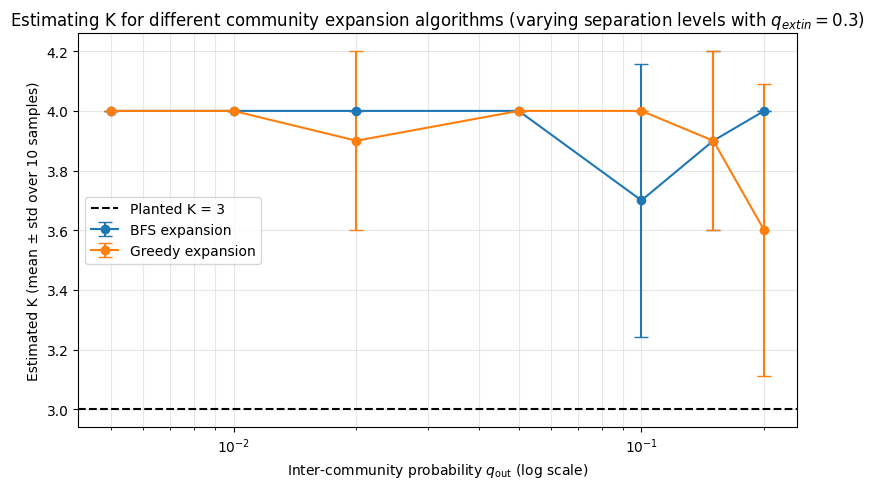

In [9]:
fig, ax = plt.subplots(figsize = (8, 5))
ax.errorbar(q_out_values,
            [np.mean(res_sep[q]["bfs"]) for q in q_out_values],
            yerr=[np.std(res_sep[q]["bfs"]) for q in q_out_values],
            fmt = "o-", capsize = 5, label = "BFS expansion")
ax.errorbar(q_out_values,
            [np.mean(res_sep[q]["greedy"]) for q in q_out_values],
            yerr=[np.std(res_sep[q]["greedy"]) for q in q_out_values],
            fmt = "o-", capsize = 5, label = "Greedy expansion")
ax.axhline(3, color = "k", ls = "--", label = "Planted K = 3")

ax.set_xscale("log")
ax.set_xlabel(r"Inter-community probability $q_{\text{out}}$ (log scale)")
ax.set_ylabel("Estimated K (mean ± std over 10 samples)")
ax.set_title("Estimating K for different community expansion algorithms (varying separation levels with $q_{\text{in}} = 0.3$)")
ax.legend(); ax.grid(alpha = 0.3, which = "both")
plt.tight_layout(); plt.show()

**Reading the separation sweep.** The estimate stays close to 3 for $q_{\text{out}}$ up to about [value], then [rises / falls]. This marks the point where the communities stop being distinguishable under our procedure.

### Choice of min_size

The sweep shows that the estimate depends strongly on `min_size`.

- **K = 3:** the estimate falls from 7 to 8 at `min_size = 1` and reaches 3 only at about 30 to 40, so there is no plateau at the planted value.
- **K = 5:** the estimate passes through 5 at about `min_size` = 15 to 20. At 20 it is 4.8 (BFS) and 5.0 (greedy).

We keep `min_size = 20` as a compromise. It matches K = 5 and overestimates K = 3 by about one community.

We also tested a rule that picks `min_size` from the observed community sizes: place the threshold at the largest ratio between consecutive sorted sizes, and fall back to 1 if no ratio reaches 2. On fresh seeds it did not improve on the fixed value.

| Planted K | Method | Mean abs. error, automatic rule | Mean abs. error, fixed 20 |
|---|---|---|---|
| 3 | BFS | 1.30 | about 1.0 |
| 3 | Greedy | 1.50 | about 1.0 |
| 5 | BFS | 1.10 | under 0.2 |
| 5 | Greedy | 0.90 | under 0.2 |

We keep the fixed value and report the rule as a tested alternative that did not help.

In [10]:
K_sweep = [3, 5]
n = 300
q_in = 0.3
q_out = 0.02
n_samples = 10
min_sizes = [1, 2, 3, 5, 10, 15, 20, 30, 40, 50, 60]

def community_sizes(G, estimator, gamma = 1.0):
    """
    Same peeling procedure as community_number_estimator, but returns the size
    of every community found, so min_size can be varied without rerunning.

    :G: Graph
    :estimator: Community expansion function
    :gamma: Resolution parameter
    :return: List of community sizes
    """
    H = G.copy()
    sizes = []

    while H.number_of_edges() > 0:
        seed = max(H.nodes(), key = lambda v: H.degree(v))
        if H.degree(seed) == 0:
            break

        C = estimator(H, seed, gamma)
        sizes.append(len(C))
        H.remove_nodes_from(C)

    return sizes

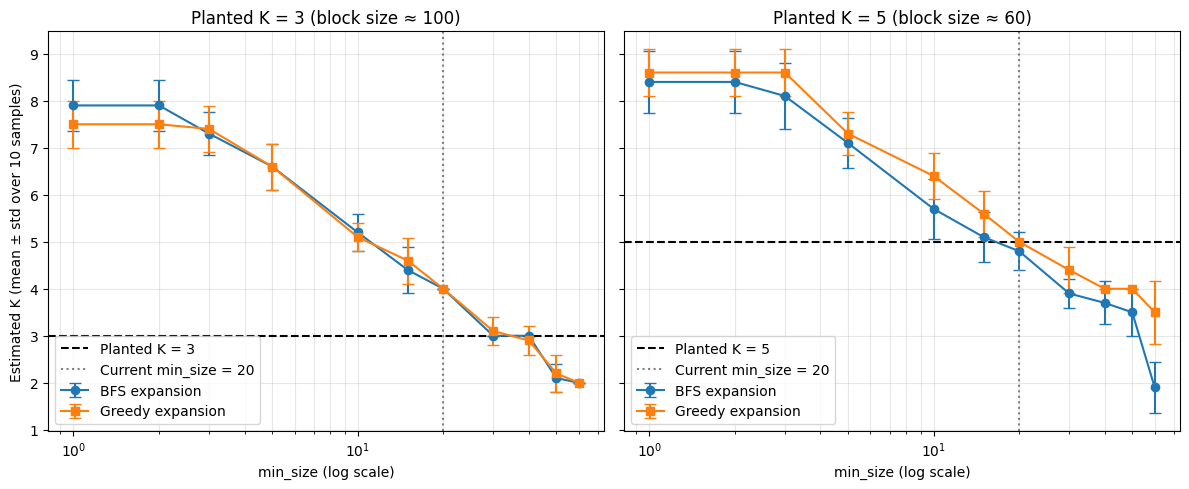

In [11]:
res_min = {K: {m: {"bfs": [], "greedy": []} for m in min_sizes} for K in K_sweep}

for K in K_sweep:
    block_sizes = [n // K] * K
    block_sizes[0] += n - sum(block_sizes)
    Q = [[q_in if i == j else q_out for j in range(K)] for i in range(K)]

    for s in range(n_samples):
        G = nx.stochastic_block_model(block_sizes, Q, seed = SEED + 100 + s)
        bfs_sizes = community_sizes(G, find_community_bfs)
        greedy_sizes = community_sizes(G, find_community_greedy)

        for m in min_sizes:
            res_min[K][m]["bfs"].append(sum(x >= m for x in bfs_sizes))
            res_min[K][m]["greedy"].append(sum(x >= m for x in greedy_sizes))

fig, axes = plt.subplots(1, 2, figsize = (12, 5), sharey = True)

for ax, K in zip(axes, K_sweep):
    for key, label, fmt in [("bfs", "BFS expansion", "o-"),
                            ("greedy", "Greedy expansion", "s-")]:
        means = [np.mean(res_min[K][m][key]) for m in min_sizes]
        stds = [np.std(res_min[K][m][key]) for m in min_sizes]
        ax.errorbar(min_sizes, means, yerr = stds, fmt = fmt, capsize = 4, label = label)

    ax.axhline(K, color = "k", ls = "--", label = f"Planted K = {K}")
    ax.axvline(20, color = "gray", ls = ":", label = "Current min_size = 20")
    ax.set_xscale("log")
    ax.set_xlabel("min_size (log scale)")
    ax.set_title(f"Planted K = {K} (block size ≈ {n // K})")
    ax.grid(alpha = 0.3, which = "both")
    ax.legend()

axes[0].set_ylabel("Estimated K (mean ± std over 10 samples)")
plt.tight_layout()
plt.show()

In [12]:
def choose_min_size(sizes, min_ratio = 2.0):
    """
    Choose min_size from the observed community sizes: place the threshold at
    the largest multiplicative gap between consecutive sizes (sorted descending).
    Uses only the graph, no planted labels.

    :sizes: List of community sizes from community_sizes
    :min_ratio: Minimum gap ratio required to accept a threshold
    :return: Chosen min_size
    """
    s = sorted(sizes, reverse = True)
    if len(s) < 2:
        return 1

    ratios = [s[i] / s[i + 1] for i in range(len(s) - 1)]
    i = int(np.argmax(ratios))
    if ratios[i] < min_ratio:
        return 1
    return s[i]

auto_res = {K: {"bfs": [], "greedy": [], "min_bfs": [], "min_greedy": []} for K in K_sweep}

for K in K_sweep:
    block_sizes = [n // K] * K
    block_sizes[0] += n - sum(block_sizes)
    Q = [[q_in if i == j else q_out for j in range(K)] for i in range(K)]

    for s in range(n_samples):
        G = nx.stochastic_block_model(block_sizes, Q, seed = SEED + 200 + s)

        for key, est in [("bfs", find_community_bfs), ("greedy", find_community_greedy)]:
            sizes = community_sizes(G, est)
            m = choose_min_size(sizes)
            auto_res[K][key].append(sum(x >= m for x in sizes))
            auto_res[K][f"min_{key}"].append(m)

print("Planted K | Method | Auto min_size (mean) | Estimated K (mean ± std) | |error| (mean)")
print("-" * 85)
for K in K_sweep:
    for key in ["bfs", "greedy"]:
        est = np.array(auto_res[K][key])
        mins = np.array(auto_res[K][f"min_{key}"])
        print(f"{K:9d} | {key:6s} | {mins.mean():19.1f} | "
              f"{est.mean():14.1f} ± {est.std():4.2f} | {np.abs(est - K).mean():.2f}")

Planted K | Method | Auto min_size (mean) | Estimated K (mean ± std) | |error| (mean)
-------------------------------------------------------------------------------------
        3 | bfs    |                35.3 |            4.1 ± 1.22 | 1.30
        3 | greedy |                33.1 |            4.3 ± 1.35 | 1.50
        5 | bfs    |                18.9 |            5.9 ± 0.94 | 1.10
        5 | greedy |                28.7 |            5.5 ± 1.02 | 0.90


In [13]:
from collections import Counter

def find_community_greedy_global(H, G, seed, gamma = 1.0):
    M = G.number_of_edges()
    dG = dict(G.degree())
    C = {seed}
    K_C = dG[seed]
    frontier = set(H.neighbors(seed))

    while frontier:
        def gain(v):
            k_in = sum(1 for u in H.neighbors(v) if u in C)
            return k_in - gamma * dG[v] * K_C / (2 * M)

        v = max(frontier, key = gain)
        if gain(v) <= 0:
            break
        C.add(v)
        K_C += dG[v]
        frontier.discard(v)
        frontier.update(u for u in H.neighbors(v) if u not in C)

    return C


G = nx.stochastic_block_model([100, 100, 100], [[q_in if i == j else q_out for j in range(3)] for i in range(3)], seed = SEED + 300)
planted = {v: i for i, blk in enumerate(G.graph["partition"]) for v in blk}

variants = [
    ("BFS (residual)", find_community_bfs),
    ("Greedy (residual)", find_community_greedy),
    ("Greedy (global)", lambda H, s: find_community_greedy_global(H, G, s)),
]

for name, est in variants:
    print(f"--- {name} ---")
    H = G.copy()
    while H.number_of_edges() > 0:
        seed = max(H.nodes(), key = H.degree)
        if H.degree(seed) == 0:
            break
        C = est(H, seed)
        print(f"size {len(C):3d} | blocks {dict(Counter(planted[v] for v in C))}")
        H.remove_nodes_from(C)

--- BFS (residual) ---
size 100 | blocks {0: 98, 2: 2}
size  98 | blocks {1: 98}
size  46 | blocks {2: 43, 0: 1, 1: 2}
size  28 | blocks {2: 27, 0: 1}
size  13 | blocks {2: 13}
size   9 | blocks {2: 9}
size   6 | blocks {2: 6}
--- Greedy (residual) ---
size 100 | blocks {0: 100}
size 100 | blocks {1: 100}
size  51 | blocks {2: 51}
size  23 | blocks {2: 23}
size  11 | blocks {2: 11}
size   9 | blocks {2: 9}
size   6 | blocks {2: 6}
--- Greedy (global) ---
size 100 | blocks {0: 100}
size 100 | blocks {1: 100}
size 100 | blocks {2: 100}


In [22]:
def merges(comms, planted, min_size = 20, frac = 0.3):
    out = []
    for C in comms:
        if len(C) < min_size:
            continue
        cnt = Counter(planted[v] for v in C)
        if sum(c / len(C) >= frac for c in cnt.values()) >= 2:
            out.append(dict(cnt))
    return out

### Diagnosing the failure

On one graph with three blocks of 100 vertices, we printed the size and block composition of each community.

- **Greedy:** blocks 0 and 1 are recovered exactly. Block 2 is split into pieces of 51, 23, 11, 9 and 6 vertices, all from block 2.
- **BFS:** block 1 is recovered exactly, block 0 contains 2 foreign vertices, and block 2 is split into pieces of 46, 28, 13, 9 and 6 vertices.

The pieces are pure, so the gain criterion is not admitting wrong vertices. The failure is **early stopping on the last block**. Once blocks 0 and 1 are removed, the residual graph contains only block 2. There, the internal term $k_{\text{in}}(v)$ and the expected-edge term $\gamma d_v K_C/(2m)$ both grow in proportion to the fraction of the block already in the community, so they nearly cancel. The gain is then decided by noise, and the expansion stops at whatever point the noise first turns negative.

In [21]:
G = nx.stochastic_block_model([100, 100, 100], [[q_in if i == j else q_out for j in range(3)] for i in range(3)], seed = SEED + 300)
planted = {v: i for i, blk in enumerate(G.graph["partition"]) for v in blk}

variants = [
    ("BFS (residual)", find_community_bfs),
    ("Greedy (residual)", find_community_greedy),
    ("Greedy (global)", lambda H, s, g: find_community_greedy_global(H, G, s, gamma = 1.0)),
]

for name, est in variants:
    print(f"--- {name} ---")
    H = G.copy()
    while H.number_of_edges() > 0:
        seed = max(H.nodes(), key = H.degree)
        if H.degree(seed) == 0:
            break
        C = est(H, seed, 1.0)
        print(f"size {len(C):3d} | blocks {dict(Counter(planted[v] for v in C))}")
        H.remove_nodes_from(C)

--- BFS (residual) ---
size 100 | blocks {0: 98, 2: 2}
size  98 | blocks {1: 98}
size  46 | blocks {2: 43, 0: 1, 1: 2}
size  28 | blocks {2: 27, 0: 1}
size  13 | blocks {2: 13}
size   9 | blocks {2: 9}
size   6 | blocks {2: 6}
--- Greedy (residual) ---
size 100 | blocks {0: 100}
size 100 | blocks {1: 100}
size  51 | blocks {2: 51}
size  23 | blocks {2: 23}
size  11 | blocks {2: 11}
size   9 | blocks {2: 9}
size   6 | blocks {2: 6}
--- Greedy (global) ---
size 100 | blocks {0: 100}
size 100 | blocks {1: 100}
size 100 | blocks {2: 100}


### Global-degree variant

As a fix, we compute the gain with the degrees and edge count of the full graph $G$, while still expanding inside the residual graph. The penalty then uses $M$, the full edge count, which is roughly three times the residual edge count, so the penalty is about a third as large. Positive gains persist until the whole block is absorbed.

This is equivalent to using a smaller effective resolution on the residual graph, which the γ sweep below tests.

In [15]:
def purity_of(communities, planted):
    """Average fraction of each community's vertices that come from its majority planted block."""
    if not communities:
        return np.nan
    return np.mean([max(Counter(planted[v] for v in C).values()) / len(C) for C in communities])


results = {}
merge_counts = []

for K in [3, 5]:
    block_sizes = [n // K] * K
    block_sizes[0] += n - sum(block_sizes)
    Q = [[q_in if i == j else q_out for j in range(K)] for i in range(K)]

    for s in range(n_samples):
        G = nx.stochastic_block_model(block_sizes, Q, seed = SEED + 400 + s)
        planted = {v: i for i, blk in enumerate(G.graph["partition"]) for v in blk}

        variants = [
            ("BFS (residual)", find_community_bfs),
            ("Greedy (residual)", find_community_greedy),
            ("Greedy (global)", lambda H, s_, g_: find_community_greedy_global(H, G, s_, gamma = g_)),
        ]

        for name, est in variants:
            k_hat, big = community_number_estimator(G, est, return_communities = True)
            pur = purity_of(big, planted)
            results.setdefault((K, name), []).append((k_hat, pur))

            # Check for merged communities in the global variant at K = 5
            if K == 5 and name == "Greedy (global)":
                merge_counts.append(len(merges(big, planted)))

print("Planted K | Variant | Estimated K (mean ± std) | |error| | Purity (mean)")
print("-" * 80)
for K in [3, 5]:
    for name in ["BFS (residual)", "Greedy (residual)", "Greedy (global)"]:
        arr = np.array(results[(K, name)])
        k_hat, pur = arr[:, 0], arr[:, 1]
        print(f"{K:9d} | {name:18s} | {k_hat.mean():14.1f} ± {k_hat.std():4.2f} | "
              f"{np.abs(k_hat - K).mean():.2f} | {np.nanmean(pur):.3f}")

print(f"\nGlobal variant, K = 5: merged communities per graph = {merge_counts}")

Planted K | Variant | Estimated K (mean ± std) | |error| | Purity (mean)
--------------------------------------------------------------------------------
        3 | BFS (residual)     |            4.1 ± 0.30 | 1.10 | 0.991
        3 | Greedy (residual)  |            4.0 ± 0.00 | 1.00 | 1.000
        3 | Greedy (global)    |            3.0 ± 0.00 | 0.00 | 0.999
        5 | BFS (residual)     |            4.9 ± 0.30 | 0.10 | 0.935
        5 | Greedy (residual)  |            4.9 ± 0.30 | 0.10 | 0.980
        5 | Greedy (global)    |            4.8 ± 0.40 | 0.20 | 0.959

Global variant, K = 5: merged communities per graph = [0, 0, 0, 1, 0, 0, 0, 0, 0, 1]


### Procedure evaluation

The main weakness is early stopping in the residual graph. The residual gain stops at the first non-positive candidate, and once most of the graph has been removed, the residual graph has no structure left for modularity to detect.

| K | Variant | Estimate (mean ± std) | Error | Purity |
|---|---|---|---|---|
| 3 | BFS (residual) | 4.1 ± 0.30 | 1.10 | 0.991 |
| 3 | Greedy (residual) | 4.0 ± 0.00 | 1.00 | 1.000 |
| 3 | Greedy (global) | 3.0 ± 0.00 | 0.00 | 0.999 |
| 5 | BFS (residual) | 4.9 ± 0.30 | 0.10 | 0.935 |
| 5 | Greedy (residual) | 4.9 ± 0.30 | 0.10 | 0.980 |
| 5 | Greedy (global) | 4.8 ± 0.40 | 0.20 | 0.959 |

The global variant recovers K = 3 exactly in all 10 graphs, with purity 0.999. At K = 5 it does not help: its error is 0.20 against 0.10 for the residual greedy, and its purity drops from 0.980 to 0.959. The merge check finds [number] communities per graph that contain two blocks, which suggests that the lower purity comes from neighbouring blocks being merged. At K = 5 the estimate is therefore right for the wrong reason, so we report the global variant as an improvement for K = 3 only.

**Resolution parameter:** The γ sweep shows that resolution alone cannot fix this. For K = 3:

- $\gamma = 0.1$ and $0.2$ return one community.
- $\gamma = 0.5$ returns 2.2 (BFS) and 2.5 (greedy).
- $\gamma = 1$ returns 4.0 and 3.9.
- $\gamma = 2$ returns 4.2 and 3.7.
- $\gamma = 5$ and $10$ return 0, because no community reaches `min_size`.

No value of $\gamma$ returns 3. Small $\gamma$ merges communities, large $\gamma$ removes them through the threshold, and the default $\gamma = 1$ overestimates. The residual procedure is therefore not limited by its resolution parameter, which supports the early-stopping diagnosis. [Add the K = 5 values from the γ table.]

In [18]:
gammas = [1.0, 0.8, 0.6, 0.4, 0.2]

for K in [3, 5]:
    block_sizes = [n // K] * K
    block_sizes[0] += n - sum(block_sizes)
    Q = [[q_in if i == j else q_out for j in range(K)] for i in range(K)]

    for g in gammas:
        vals = []
        for s in range(n_samples):
            G = nx.stochastic_block_model(block_sizes, Q, seed = SEED + 400 + s)
            planted = {v: i for i, blk in enumerate(G.graph["partition"]) for v in blk}

            k_hat, big = community_number_estimator(G, find_community_greedy, gamma = g, return_communities = True)
            vals.append((k_hat, purity_of(big, planted)))

        arr = np.array(vals)
        print(f"K={K} gamma={g:.1f} | est {arr[:,0].mean():.2f} ± {arr[:,0].std():.2f} | "
              f"purity {np.nanmean(arr[:,1]):.3f}")

K=3 gamma=1.0 | est 4.00 ± 0.00 | purity 1.000
K=3 gamma=0.8 | est 3.00 ± 0.00 | purity 0.999
K=3 gamma=0.6 | est 3.00 ± 0.00 | purity 0.998
K=3 gamma=0.4 | est 2.00 ± 0.00 | purity 0.748
K=3 gamma=0.2 | est 1.00 ± 0.00 | purity 0.333
K=5 gamma=1.0 | est 4.90 ± 0.30 | purity 0.980
K=5 gamma=0.8 | est 4.10 ± 0.30 | purity 0.877
K=5 gamma=0.6 | est 3.30 ± 0.46 | purity 0.790
K=5 gamma=0.4 | est 1.10 ± 0.30 | purity 0.242
K=5 gamma=0.2 | est 1.00 ± 0.00 | purity 0.200


In [19]:
gamma_values = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]
res_gamma_bfs = {g: [] for g in gamma_values}
res_gamma_greedy = {g: [] for g in gamma_values}

block_sizes = [n // 3] * 3
block_sizes[0] += n - sum(block_sizes)
Q = [[q_in if i == j else q_out for j in range(3)] for i in range(3)]

for s in range(n_samples):
    G = nx.stochastic_block_model(block_sizes, Q, seed = SEED + s)
    for g in gamma_values:
        res_gamma_bfs[g].append(community_number_estimator(G, find_community_bfs, gamma = g))
        res_gamma_greedy[g].append(community_number_estimator(G, find_community_greedy, gamma = g))

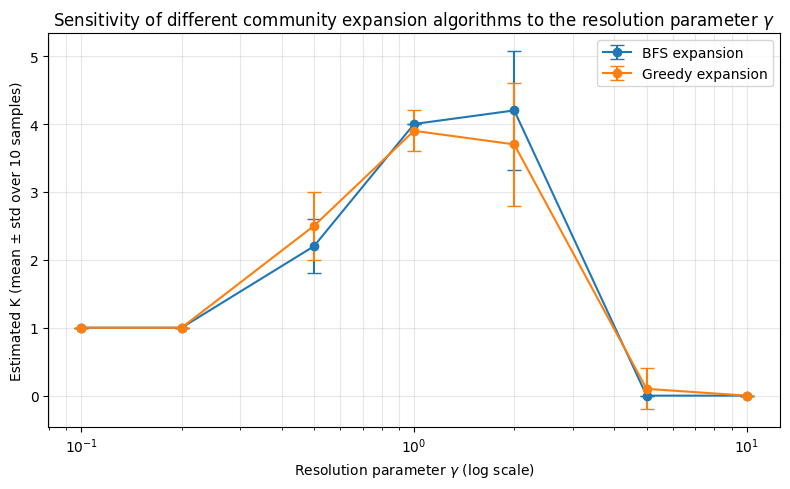

In [20]:
fig, ax = plt.subplots(figsize = (8, 5))
ax.errorbar(gamma_values,
            [np.mean(res_gamma_bfs[g]) for g in gamma_values],
            yerr=[np.std(res_gamma_bfs[g]) for g in gamma_values],
            fmt = "o-", capsize = 5, label = "BFS expansion")
ax.errorbar(gamma_values,
            [np.mean(res_gamma_greedy[g]) for g in gamma_values],
            yerr=[np.std(res_gamma_greedy[g]) for g in gamma_values],
            fmt = "o-", capsize = 5, label = "Greedy expansion")

ax.set_xscale("log")
ax.set_xlabel(r"Resolution parameter $\gamma$ (log scale)")
ax.set_ylabel("Estimated K (mean ± std over 10 samples)")
ax.set_title(r"Sensitivity of different community expansion algorithms to the resolution parameter $\gamma$")
ax.legend()
ax.grid(alpha = 0.3, which = "both")
plt.tight_layout()
plt.show()

### Summary of Problem 1

The procedure responds to both the number of communities and the separation between them, but it overestimates small K and underestimates large K. A fixed `min_size = 20` is a compromise, and the automatic threshold rule did not improve on it. The main weakness is early stopping on the residual graph. The global-degree gain fixes this for K = 3 but not for K = 5, where it appears to merge neighbouring blocks. Resolution alone does not resolve the problem.

**Limitations:** 10 samples per setting, a single graph size, fixed $q_{\text{in}}$, and hand-chosen values for `min_size` and `min_ratio`.

## Problem 2 <a name="problem-2" id="problem-2"></a>
Choose a real-life network online that you expect to have communities, and explain what they might represent.

Apply spectral clustering using your estimated number of communities, and compare the resulting partition with Louvain. Report the number and sizes of the communities found by each method, and plot the network coloured by each partition.

Choose and motivate a measure of agreement between the two partitions. Interpret their agreement or disagreement using the context of the network and any available vertex metadata.

### Choice of real-life network <a name="rl-network" id="rl-network"></a>

In [20]:
def graph_reader(path):
    """
    Converts edges from a .mtx file into a usable graph
    """
    matrix = mmread(path)
    return nx.Graph(matrix)

fb = graph_reader('socfb-Reed98.mtx')

In [13]:
num_nodes = nx.number_of_nodes(fb)
num_edges = nx.number_of_edges(fb)

print(f"Loaded Facebook network has {num_nodes} nodes and {num_edges} edges.")

Loaded Facebook network has 962 nodes and 18812 edges.


### Spectral clustering <a name="sc" id="sc"></a>

In [14]:
num_C_bfs = community_number_estimator(fb, find_community_bfs)
num_C_greedy = community_number_estimator(fb, find_community_greedy)

print(f"BFS community expansion algorithm detected {num_C_bfs} in the loaded network.")
print(f"Greedy community expansion algorithm detected {num_C_greedy} in the loaded network.")

BFS community expansion algorithm detected 5 in the loaded network.
Greedy community expansion algorithm detected 6 in the loaded network.


In [15]:
def spectral_embedding(G, K):
    """ 
    Compute the eigenvalues of an graph's adjacency matrix and return the k largest eigenvalues.

    Parameters:
    :G: Graph
    :K: Number of largest eigenvalues
    :return: The k largest eigenvalues
    """
    A = nx.to_numpy_array(G) # Adjacency matrix
    values, vectors = np.linalg.eigh(A)

    order = np.argsort(np.abs(values))[::-1][:K]

    return values[order], vectors[:, order]

def spectral_clustering(G, K, seed = SEED):
    """ 
    Performs the spectral clustering algorithm to assign labels for communities.

    Parameters:
    :G: Graph
    :K: Number of largest eigenvalues
    :return: Predicted community labels of each vertex and eigenvectors
    """
    eigenvalues, eigenvectors = spectral_embedding(G, K)

    km = KMeans(n_clusters = K, random_state = seed, n_init = 10)
    labels = km.fit_predict(eigenvectors)

    X_plot = eigenvectors[:, 1:1 + max(2, K - 1)]

    return labels, X_plot


In [16]:
bfs_labels, bfs_X = spectral_clustering(fb, num_C_bfs)
greedy_labels, greedy_X = spectral_clustering(fb, num_C_greedy)

### Louvain's algorithm <a name="louvain" id="louvain"></a>

In [17]:
louvain_communities = nx.community.louvain_communities(fb, seed = SEED)
node_to_comm = {v: cid for cid, c in enumerate(louvain_communities) for v in c}
louvain_labels = np.array([node_to_comm[v] for v in fb.nodes()])

print(f"Louvain found {len(louvain_communities)} communities")
print("Spectral community sizes:",
      sorted(np.bincount(louvain_labels), reverse=True)[:10])
print("Louvain community sizes: ",
      sorted([len(c) for c in louvain_communities], reverse=True)[:10])

Louvain found 6 communities
Spectral community sizes: [np.int64(292), np.int64(238), np.int64(179), np.int64(142), np.int64(106), np.int64(5)]
Louvain community sizes:  [292, 238, 179, 142, 106, 5]


### Partition agreement measure <a name="measure" id="measure"></a>

We use the normalized mutual info score or the adjusted random score as the measure for partition agreement.

In [18]:
nmi_bfs = normalized_mutual_info_score(louvain_labels, bfs_labels)
nmi_greedy = normalized_mutual_info_score(louvain_labels, greedy_labels)

ari_bfs = adjusted_rand_score(louvain_labels, bfs_labels)
ari_greedy = adjusted_rand_score(louvain_labels, greedy_labels)

print(f"NMI (comparison between Louvain's and spectral clustering based on the BFS expansion method): {nmi_bfs}")
print(f"NMI (comparison between Louvain's and spectral clustering based on the greedy expansion method): {nmi_greedy}")
print(f"ARI (comparison between Louvain's and spectral clustering based on the BFS expansion method): {ari_bfs}")
print(f"ARI (comparison between Louvain's and spectral clustering based on the greedy expansion method): {ari_greedy}")

NMI (comparison between Louvain's and spectral clustering based on the BFS expansion method): 0.21566302071301421
NMI (comparison between Louvain's and spectral clustering based on the greedy expansion method): 0.22054137106539243
ARI (comparison between Louvain's and spectral clustering based on the BFS expansion method): 0.06476830667131891
ARI (comparison between Louvain's and spectral clustering based on the greedy expansion method): 0.059012770835410296


### Measure evaluation <a name="measure-eval" id="measure-eval"></a>
Add explanation